# Machine Learning Based Lung Cancer Risk Assessment and Classification

The primary objective of this project is to develop a machine learning-based system for assessing and classifying lung cancer risk using relevant lifestyle and health-related factors.

**dataset**
 
The dataset contains demographic, lifestyle and health-related information from individuals, including factors such as age, gender, smoking habits, and various reported symptoms associated with lung cancer. It includes a target variable indicating lung cancer risk, making it suitable for exploring relationships between these factors. [1] 

**project specific objectives** 
1. Data Preprocessing: Prepare and transform the dataset for model development.
2. Model Training and Evaluation: Train, compare and evaluate classification models.
3. Model Interpretation: Analyse model performance and identify influential features.
4. Model Deployment: Deploy the selected model through a simple, accessible web application. 

**References**

[1] ‘Lung Cancer’. Accessed: Nov. 19, 2026. [Online]. Available: https://www.kaggle.com/datasets/mysarahmadbhat/lung-cancer


In [25]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import math
from pathlib import Path

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate
from sklearn.metrics import recall_score, classification_report, ConfusionMatrixDisplay
from sklearn.base import clone

from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline


## Load dataset

Load the CSV and inspect the first rows.

In [2]:
project_dir = Path.cwd()
data_dir = project_dir / "dataset" 

lung_cancer_df = pd.read_csv(data_dir / "survey_lung_cancer.csv")
lung_cancer_df.head()

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
0,M,69,1,2,2,1,1,2,1,2,2,2,2,2,2,YES
1,M,74,2,1,1,1,2,2,2,1,1,1,2,2,2,YES
2,F,59,1,1,1,2,1,2,1,2,1,2,2,1,2,NO
3,M,63,2,2,2,1,1,1,1,1,2,1,1,2,2,NO
4,F,63,1,2,1,1,1,1,1,2,1,2,2,1,1,NO


**Data pre-processing and Visualisation** 

- Check for missing and null values.
- Identify and handle duplicate records.
- Inspect data types and feature consistency.
- Identify and handle inconsistent or invalid values.

In [3]:
lung_cancer_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 309 entries, 0 to 308
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   GENDER                 309 non-null    str  
 1   AGE                    309 non-null    int64
 2   SMOKING                309 non-null    int64
 3   YELLOW_FINGERS         309 non-null    int64
 4   ANXIETY                309 non-null    int64
 5   PEER_PRESSURE          309 non-null    int64
 6   CHRONIC DISEASE        309 non-null    int64
 7   FATIGUE                309 non-null    int64
 8   ALLERGY                309 non-null    int64
 9   WHEEZING               309 non-null    int64
 10  ALCOHOL CONSUMING      309 non-null    int64
 11  COUGHING               309 non-null    int64
 12  SHORTNESS OF BREATH    309 non-null    int64
 13  SWALLOWING DIFFICULTY  309 non-null    int64
 14  CHEST PAIN             309 non-null    int64
 15  LUNG_CANCER            309 non-null    str  
dtypes

In [4]:
lung_cancer_df.isnull().sum()

GENDER                   0
AGE                      0
SMOKING                  0
YELLOW_FINGERS           0
ANXIETY                  0
PEER_PRESSURE            0
CHRONIC DISEASE          0
FATIGUE                  0
ALLERGY                  0
WHEEZING                 0
ALCOHOL CONSUMING        0
COUGHING                 0
SHORTNESS OF BREATH      0
SWALLOWING DIFFICULTY    0
CHEST PAIN               0
LUNG_CANCER              0
dtype: int64

In [5]:
lung_cancer_df.duplicated().sum()

np.int64(33)

Drop duplicated rows from the dataframe

In [6]:
data_df = lung_cancer_df.drop_duplicates().reset_index(drop=True) # Remove duplicate rows


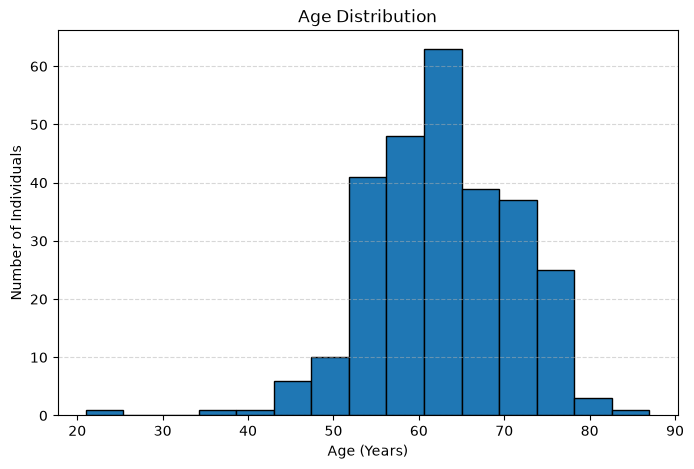

In [7]:
# Age Distribution Histogram
plt.figure(figsize=(8, 5))

plt.hist(data_df['AGE'], bins=15, edgecolor='black')

plt.title('Age Distribution')
plt.xlabel('Age (Years)')
plt.ylabel('Number of Individuals')

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

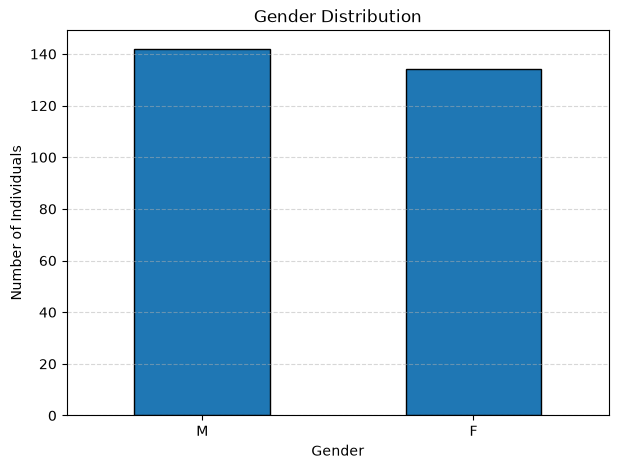

In [8]:
# Gender Distribution Bar Graph
gender_counts = data_df['GENDER'].value_counts()

plt.figure(figsize=(7, 5))
gender_counts.plot(kind='bar', edgecolor='black')

plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Number of Individuals')
plt.xticks(rotation=0)

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

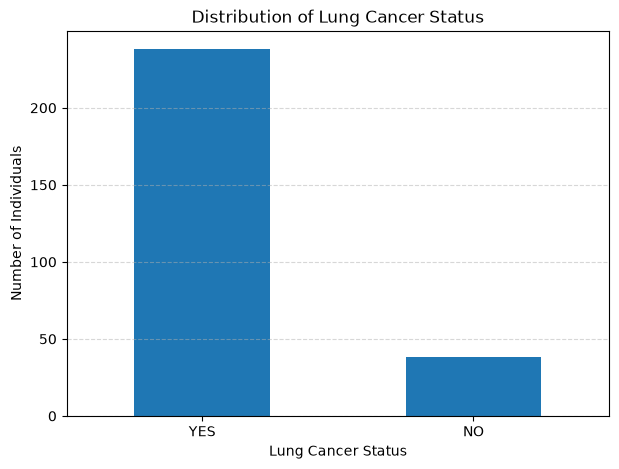

In [9]:
# Count records in each category
cancer_counts = data_df['LUNG_CANCER'].value_counts()

# Plot bar graph
plt.figure(figsize=(7, 5))
cancer_counts.plot(kind='bar')

plt.title('Distribution of Lung Cancer Status')
plt.xlabel('Lung Cancer Status')
plt.ylabel('Number of Individuals')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

# Feature and target Encoding

`GENDER` and `LUNG_CANCER` columns encoding



In [10]:
gender_code = {'F': 0, 'M': 1}
target_code = {'NO': 0, 'YES': 1}

data_df['GENDER'] = data_df['GENDER'].map(gender_code)
data_df['LUNG_CANCER'] = data_df['LUNG_CANCER'].map(target_code)

## Train / test split

A stratified 80/20 split keeps the `YES` / `NO` ratio the same in both parts.

In [11]:
RANDOM_STATE = 42

# Split the dataset into features and target variable
X = data_df.drop('LUNG_CANCER', axis=1)
y = data_df['LUNG_CANCER']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y  # maintain the original class distribution in both splits
)

print("Training target distribution:")
print(y_train.value_counts())
print("\nTest target distribution:")
print(y_test.value_counts())

Training target distribution:
LUNG_CANCER
1    190
0     30
Name: count, dtype: int64

Test target distribution:
LUNG_CANCER
1    48
0     8
Name: count, dtype: int64


## Class imbalance handling

The dataset exhibits class imbalance, with significantly more `YES` than `NO` records. The training data is oversampled with SMOTENC to balance the classes. 

In [12]:
# AGE is the only continuous feature, so we exclude it from the categorical features list.
categorical_features = [col for col in X_train.columns if col != 'AGE']

smotenc = SMOTENC(
    categorical_features=categorical_features,
    random_state=RANDOM_STATE
)

# Resample the training dataset only.
X_train_smotenc, y_train_smotenc = smotenc.fit_resample(X_train, y_train)

# Inspect the resampled training dataset.
print("Resampled target distribution:")
print(y_train_smotenc.value_counts())

Resampled target distribution:
LUNG_CANCER
1    190
0    190
Name: count, dtype: int64


## Model training and evaluation

In [13]:
models = {
    'Logistic regression'  : LogisticRegression(max_iter=1000),
    'Linear SVC'           : LinearSVC(C=20, random_state=RANDOM_STATE),
    'k-NN'                 : KNeighborsClassifier(n_neighbors=30),
    'Random forest'        : RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
}

In [22]:
# This function was developed with assistance from ChatGPT
# to streamline model training and evaluation using Scikit-learn metrics.

def evaluate_models(models, X_train, X_test, y_train, y_test):

    predictions = {}

    for name, model in models.items():

        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)
        predictions[name] = y_pred

        # Classification report for this model
        print(f"{name}")
        print(classification_report(y_test, y_pred, zero_division=0))
        print("-" * 60)

    # Plot confusion matrices
    labels = np.unique(
        np.concatenate([np.asarray(y_train), np.asarray(y_test)])
    )

    n_models = len(predictions)
    n_cols = 2
    n_rows = math.ceil(n_models / n_cols)

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(12, 5 * n_rows),
        squeeze=False
    )

    for ax, (name, y_pred) in zip(axes.flat, predictions.items()):

        ConfusionMatrixDisplay.from_predictions(
            y_test,
            y_pred,
            labels=labels,
            display_labels=labels,
            values_format='d',
            cmap='Blues',
            colorbar=False,
            ax=ax
        )

        ax.set_title(name, fontsize=12, fontweight='bold')

    # Remove unused subplots
    for ax in axes.flat[n_models:]:
        fig.delaxes(ax)

    fig.suptitle(
        'Confusion Matrices for All Models',
        fontsize=15,
        fontweight='bold'
    )

    plt.tight_layout()
    plt.show()

Logistic regression
              precision    recall  f1-score   support

           0       0.75      0.75      0.75         8
           1       0.96      0.96      0.96        48

    accuracy                           0.93        56
   macro avg       0.85      0.85      0.85        56
weighted avg       0.93      0.93      0.93        56

------------------------------------------------------------
Linear SVC
              precision    recall  f1-score   support

           0       0.71      0.62      0.67         8
           1       0.94      0.96      0.95        48

    accuracy                           0.91        56
   macro avg       0.83      0.79      0.81        56
weighted avg       0.91      0.91      0.91        56

------------------------------------------------------------
k-NN
              precision    recall  f1-score   support

           0       0.32      0.75      0.44         8
           1       0.95      0.73      0.82        48

    accuracy            

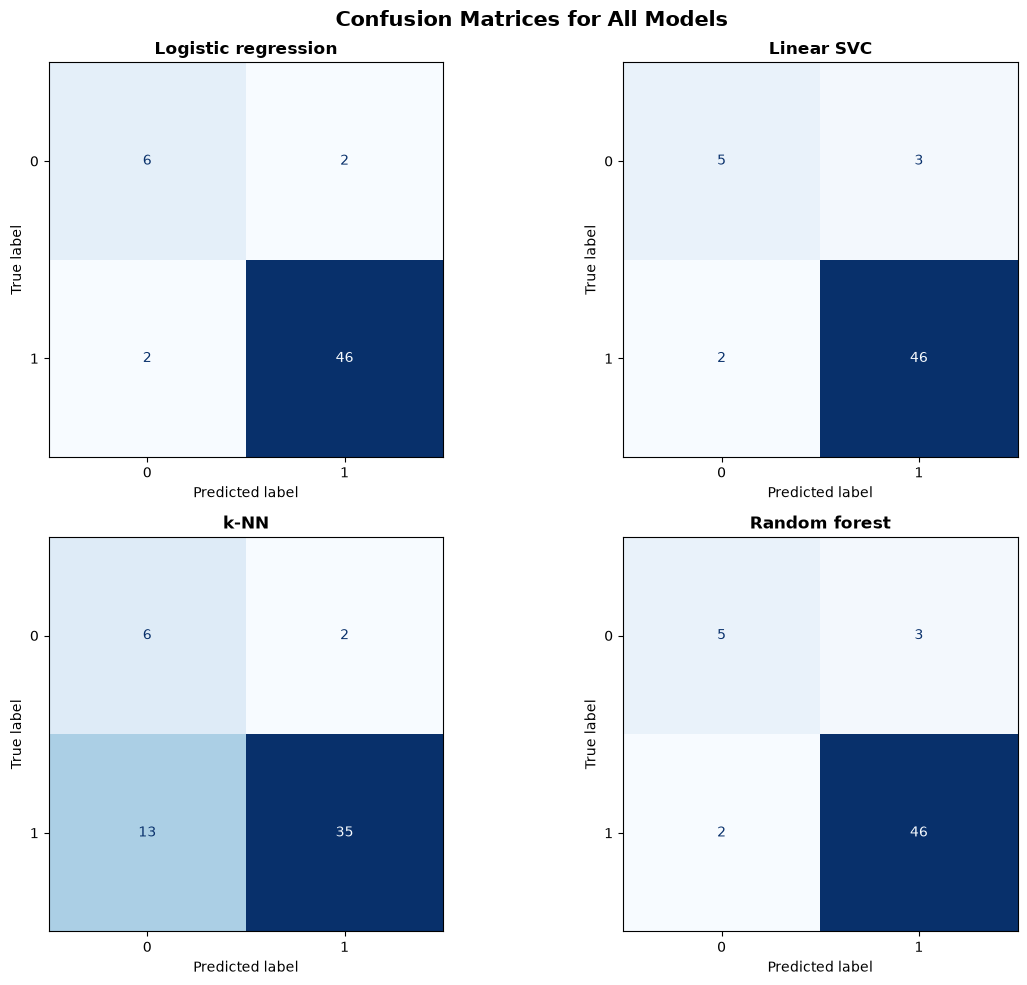

In [23]:
# Train and evaluate the models on the resampled training data
results_single = evaluate_models(models, X_train_smotenc, X_test, y_train_smotenc, y_test)
results_single

## Model evaluation using cross-validation 
**The test dataset has 8 No and 48 Yes targets**

To get a better estimate, the models are evaluated with repeated stratified 5-fold cross validation:
- Every record is used for validation.
- Stratification keeps the class ratio the same in each fold.
- SMOTENC is applied inside each training fold, so synthetic samples never leak into the validation data.

In [26]:
# Repeated stratified k-fold cross-validation implemented with assistance from Claude (Anthropic).
# SMOTENC is applied inside each training fold through an imblearn pipeline,
# so synthetic samples never leak into the validation data.

cv = RepeatedStratifiedKFold(
    n_splits=5, n_repeats=5, random_state=RANDOM_STATE
)

scoring = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro",
    "roc_auc": "roc_auc",
}

cv_rows = []
cv_raw_scores = {}

for name, model in models.items():
    pipe = Pipeline(
        steps=[
            (
                "smotenc",
                SMOTENC(
                    categorical_features=categorical_features,
                    random_state=RANDOM_STATE,
                ),
            ),
            ("model", clone(model)),
        ]
    )

    scores = cross_validate(
        pipe,
        X,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise",
    )
    cv_raw_scores[name] = scores
    cv_rows.append(
        {
            "model": name,
            "accuracy_mean": scores["test_accuracy"].mean(),
            "macro_f1_mean": scores["test_macro_f1"].mean(),
            "roc_auc_mean": scores["test_roc_auc"].mean(),
        }
    )

cv_results = pd.DataFrame(cv_rows).sort_values("macro_f1_mean", ascending=False)
cv_results

,model,accuracy_mean,macro_f1_mean,roc_auc_mean
0,Logistic regression,0.908792,0.813510,0.935441
1,Linear SVC,0.903688,0.799555,0.919541
3,Random forest,0.893442,0.775990,0.923666
2,k-NN,0.701312,0.609707,0.790079


In [178]:
import time
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

# Model training and evaluation

In [179]:
RANDOM_STATE = 42 # for reproducibility

models = {
    'Dummy Classifier'     : DummyClassifier(strategy='most_frequent'),
    'Logistic regression'  : LogisticRegression(max_iter=1000),
    'Linear SVC'           : LinearSVC(C=20, random_state=RANDOM_STATE),
    'k-NN'                 : KNeighborsClassifier(n_neighbors=30),
    'Random forest'        : RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
}

In [180]:
# This function was developed with assistance from ChatGPT
# to streamline model training and evaluation using Scikit-learn metrics.

def evaluate_models(models, X_train, X_test, y_train, y_test):

    predictions = {}

    for name, model in models.items():

        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)
        predictions[name] = y_pred

        # Classification report for this model
        print(f"{name}")
        print(classification_report(y_test, y_pred, zero_division=0))
        print("-" * 60)

    # Plot confusion matrices
    labels = np.unique(
        np.concatenate([np.asarray(y_train), np.asarray(y_test)])
    )

    n_models = len(predictions)
    n_cols = 2
    n_rows = math.ceil(n_models / n_cols)

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(12, 5 * n_rows),
        squeeze=False
    )

    for ax, (name, y_pred) in zip(axes.flat, predictions.items()):

        ConfusionMatrixDisplay.from_predictions(
            y_test,
            y_pred,
            labels=labels,
            display_labels=labels,
            values_format='d',
            cmap='Blues',
            colorbar=False,
            ax=ax
        )

        ax.set_title(name, fontsize=12, fontweight='bold')

    # Remove unused subplots
    for ax in axes.flat[n_models:]:
        fig.delaxes(ax)

    fig.suptitle(
        'Confusion Matrices for All Models',
        fontsize=15,
        fontweight='bold'
    )

    plt.tight_layout()
    plt.show()

In [181]:
# replace categorical variables with numerical values 
encoder = LabelEncoder()
categorical_columns = ['GENDER', 'LUNG_CANCER']
for col in categorical_columns:
    data_df[col] = encoder.fit_transform(data_df[col]) 


In [182]:
# Split the dataset into features and target variable
X = data_df.drop('LUNG_CANCER', axis=1)
y = data_df['LUNG_CANCER'] 


**Class Imbalance Handling**

The dataset exhibits class imbalance, with significantly more YES than NO records.
Oversample the Dataset using SMOTENC to balance the classes.


In [183]:
# balanced training data using smote oversampling technique
from imblearn.over_sampling import SMOTENC 
from sklearn.model_selection import StratifiedKFold 

In [184]:
# for categorical feature identification and SMOTENC implementation.

# Split the dataset into features and target variable.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y # stratify the split to maintain the original class distribution
)

# Identify categorical features for SMOTENC.
# AGE is the only continuous feature, so we exclude it from the categorical features list.
categorical_features = [
    col for col in X_train.columns if col != 'AGE'
]

# Apply SMOTENC to balance the training dataset.
# The test dataset remains unchanged to prevent data leakage.
smotenc = SMOTENC(
    categorical_features=categorical_features,
    random_state=RANDOM_STATE
)

# Resample the training dataset using SMOTENC.
X_train_smotenc, y_train_smotenc = smotenc.fit_resample(
    X_train, y_train
)

# Inspect the resampled training dataset.
print("Resampled target distribution:")
print(y_train_smotenc.value_counts())

Resampled target distribution:
LUNG_CANCER
1    190
0    190
Name: count, dtype: int64


Dummy Classifier
              precision    recall  f1-score   support

           0       0.14      1.00      0.25         8
           1       0.00      0.00      0.00        48

    accuracy                           0.14        56
   macro avg       0.07      0.50      0.12        56
weighted avg       0.02      0.14      0.04        56

------------------------------------------------------------
Logistic regression
              precision    recall  f1-score   support

           0       0.75      0.75      0.75         8
           1       0.96      0.96      0.96        48

    accuracy                           0.93        56
   macro avg       0.85      0.85      0.85        56
weighted avg       0.93      0.93      0.93        56

------------------------------------------------------------
Linear SVC
              precision    recall  f1-score   support

           0       0.71      0.62      0.67         8
           1       0.94      0.96      0.95        48

    accuracy

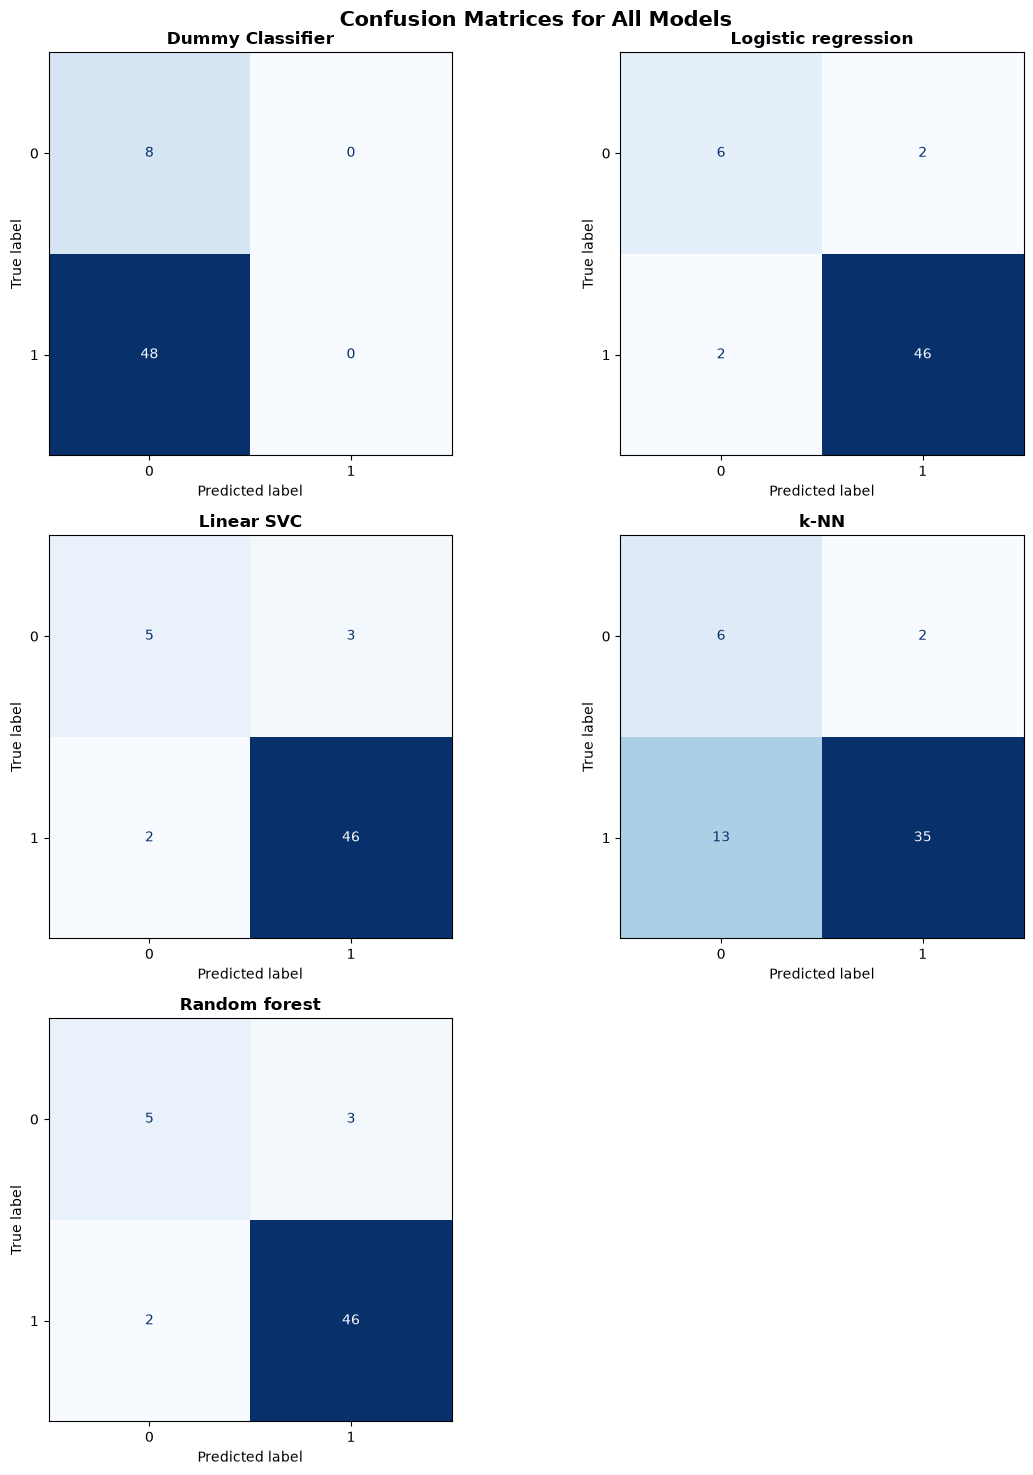

In [185]:
# train and evaluate the models on the resampled training data
results_resampled = evaluate_models(models, X_train_smotenc, X_test, y_train_smotenc, y_test)
results_resampled

# Solve class imbalance in test dataset using cross validation
**The test dataset has 8 No and 48 Yes targets**

To get a better estimate, the models are evaluated with repeated stratified 5-fold cross validation:
- Every record is used for validation.
- Stratification keeps the class ratio the same in each fold.
- SMOTENC is applied inside each training fold, so synthetic samples never leak into the validation data.

In [ ]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from imblearn.pipeline import Pipeline

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)

scoring = {
    'accuracy': 'accuracy',
    'macro_f1': 'f1_macro',
    'roc_auc': 'roc_auc',
}

cv_results = []
for name, model in models.items():
    pipe = Pipeline([
        ('smotenc', SMOTENC(categorical_features=categorical_features,
                            random_state=RANDOM_STATE)),
        ('model', model),
    ])
    scores = cross_validate(pipe, X, y, cv=cv, scoring=scoring, n_jobs=-1)
    cv_results.append({
        'model': name,
        'accuracy': f"{scores['test_accuracy'].mean():.3f}",
        'macro F1': f"{scores['test_macro_f1'].mean():.3f}",
        'ROC-AUC': f"{scores['test_roc_auc'].mean():.3f}",
    })

pd.DataFrame(cv_results)

,model,accuracy,macro F1,ROC-AUC
0,Dummy Classifier,0.138,0.121,0.500
1,Logistic regression,0.909,0.814,0.935
2,Linear SVC,0.904,0.800,0.920
3,k-NN,0.701,0.610,0.790
4,Random forest,0.893,0.776,0.924


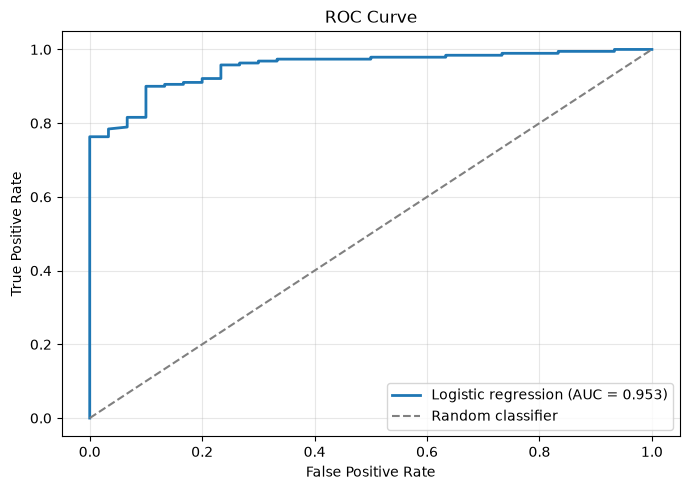

ROC-AUC: 0.953


In [ ]:
# ROC curve visualisation implemented with assistance from ChatGPT.

from sklearn.metrics import roc_curve, roc_auc_score

model_ROC = models['Logistic regression']

# Get probabilities for the positive class
y_prob = model_ROC.predict_proba(X_train)[:, 1]

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(y_train, y_prob)

# Calculate AUC
auc_score = roc_auc_score(y_train, y_prob)

# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f'Logistic regression (AUC = {auc_score:.3f})',
    linewidth=2
)

# classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='grey',
    label='Random classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')

plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"ROC-AUC: {auc_score:.3f}")

In [ ]:
# Save the model
import joblib

# Save the final model
joblib.dump(models['Logistic regression'], 'web_app/lung_cancer_risk_model.pkl')

['web_app/lung_cancer_risk_model.pkl']

In [189]:
# Feature importance implemented with assistance from Claude (Anthropic).

# Permutation importance.
# Each feature is shuffled in turn; the drop in macro F1 shows how much the model relies on it.
model_ROC = models['Logistic regression']

perm = permutation_importance(
    model_ROC,
    X_train,
    y_train,
    scoring='f1_macro',
    n_repeats=30,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    'feature': X_test.columns.str.strip(),
    'permutation mean': perm.importances_mean,
    'permutation std': perm.importances_std,
}).sort_values('permutation mean', ascending=False)

importance_df.reset_index(drop=True)

,feature,permutation mean,permutation std
0,PEER_PRESSURE,0.061358,0.022243
1,ALLERGY,0.058721,0.025844
2,CHRONIC DISEASE,0.053765,0.017025
3,FATIGUE,0.051229,0.018348
4,ALCOHOL CONSUMING,0.044481,0.025027
5,WHEEZING,0.031833,0.017083
6,COUGHING,0.027404,0.017412
7,YELLOW_FINGERS,0.020082,0.015684
8,ANXIETY,0.018571,0.014958
9,SMOKING,0.012013,0.012148


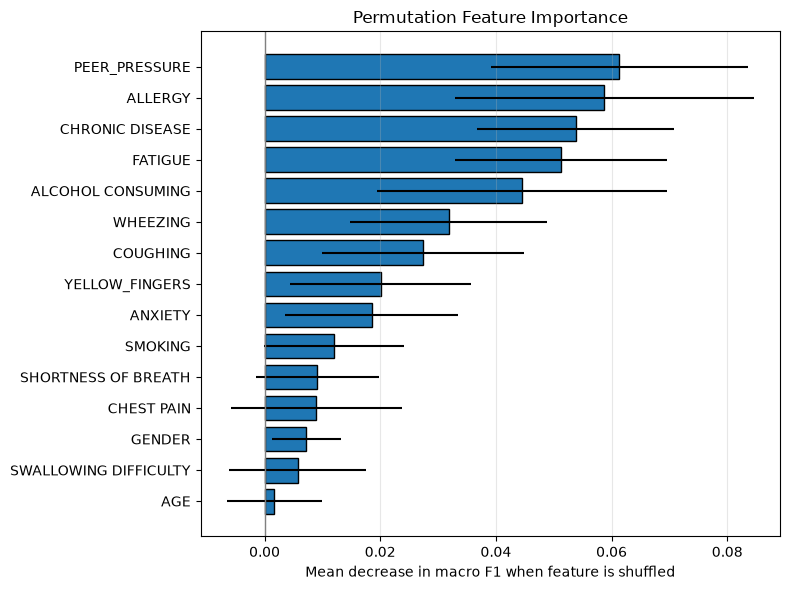

In [190]:
plot_df = importance_df.sort_values('permutation mean', ascending=True)

plt.figure(figsize=(8, 6))
plt.barh(
    plot_df['feature'],
    plot_df['permutation mean'],
    xerr=plot_df['permutation std'],
    edgecolor='black'
)
plt.axvline(0, color='grey', linewidth=1)

plt.xlabel('Mean decrease in macro F1 when feature is shuffled')
plt.title('Permutation Feature Importance')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()